In [6]:
%matplotlib widget
import matplotlib.pyplot as plt

import sys
import os

sys.path.append('.')

from math import gcd
from functools import reduce

import pickle

import numpy as np
import pandas as pd

from tqdm import tqdm

from sklearn.preprocessing import StandardScaler

import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler

from anomaly_detection_models import *

torch.set_default_dtype(torch.float64)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(device)

cpu


## Config parameters

In [7]:
data_dir = os.path.join('.', 'data')

# KAN model properties
input_size = 5000
hidden_layers = 3
output_size = 5000
epochs = 5000
learning_rate = 0.001
train_samples = 5000

MODEL_PATH = "ae_anomaly_model.pth"

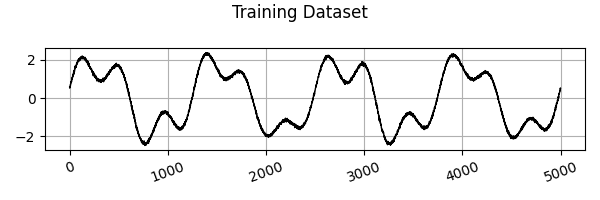

In [8]:
# Create a LSTM model    
model = Autoencoder()
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

# Load train and test dataset
df_train = pd.read_pickle(os.path.join(data_dir, "train_data.pkl"))
df_test = pd.read_pickle(os.path.join(data_dir, "test_data.pkl"))

# Graph the train dataset
fig, ax = plt.subplots(1, 1, sharex='col', figsize=(6, 2))
fig.suptitle('Training Dataset')
ax.plot(df_train.iloc[1,:], color='black', linewidth=1)
ax.grid(True)

plt.xticks(rotation=20)
fig.tight_layout()

train_tmp = []
test_tmp = []
for col in df_train.columns: 
    train_tmp.append(df_train[col])
    test_tmp.append(df_test[col])
dataset = {}
dataset["train_input"] = torch.transpose(torch.Tensor(train_tmp), 0, 1)
dataset["train_label"] = torch.transpose(torch.Tensor(train_tmp), 0, 1)
dataset["test_input"] = torch.transpose(torch.Tensor(test_tmp), 0, 1)
dataset["test_label"] = torch.transpose(torch.Tensor(test_tmp), 0, 1)

In [9]:
for epoch in range(epochs):
    model.train()
    optimizer.zero_grad()
    output = model(dataset["train_input"])
    loss = criterion(output.squeeze(), dataset["train_label"])
    loss.backward()
    optimizer.step()
    print(f"Epoch {epoch+1}/{epochs}, Loss: {loss.item():.6f}")


Epoch 1/5000, Loss: 7.675623
Epoch 2/5000, Loss: 7.774798
Epoch 3/5000, Loss: 7.646793
Epoch 4/5000, Loss: 7.615610
Epoch 5/5000, Loss: 7.618804
Epoch 6/5000, Loss: 7.591407
Epoch 7/5000, Loss: 7.558474
Epoch 8/5000, Loss: 7.533916
Epoch 9/5000, Loss: 7.506600
Epoch 10/5000, Loss: 7.475203
Epoch 11/5000, Loss: 7.435431
Epoch 12/5000, Loss: 7.395926
Epoch 13/5000, Loss: 7.343083
Epoch 14/5000, Loss: 7.289119
Epoch 15/5000, Loss: 7.224197
Epoch 16/5000, Loss: 7.155749
Epoch 17/5000, Loss: 7.079438
Epoch 18/5000, Loss: 6.992938
Epoch 19/5000, Loss: 6.903064
Epoch 20/5000, Loss: 6.803632
Epoch 21/5000, Loss: 6.700278
Epoch 22/5000, Loss: 6.588760
Epoch 23/5000, Loss: 6.471808
Epoch 24/5000, Loss: 6.351142
Epoch 25/5000, Loss: 6.224081
Epoch 26/5000, Loss: 6.095143
Epoch 27/5000, Loss: 5.961170
Epoch 28/5000, Loss: 5.826216
Epoch 29/5000, Loss: 5.687510
Epoch 30/5000, Loss: 5.548054
Epoch 31/5000, Loss: 5.406421
Epoch 32/5000, Loss: 5.264087
Epoch 33/5000, Loss: 5.120405
Epoch 34/5000, Loss

In [10]:
# === After training (continue from previous code) ===
torch.save(model.state_dict(), MODEL_PATH)
print(f"Model saved to {MODEL_PATH}")

Model saved to ae_anomaly_model.pth
